# Creating a Dataframe

In [2]:
import os
import cv2
import numpy as np
import pandas as pd


# ============================================================
# 1. Folder paths
# ============================================================

crack_path = r"D:\MASTERS\FOML\assignment\202618026_AumTailor_DS605\202618026_lab_06\448\Cracks"
non_crack_path = r"D:\MASTERS\FOML\assignment\202618026_AumTailor_DS605\202618026_lab_06\448\NonCracks"


# ============================================================
# 2. Assign labels
# ============================================================

folders = {
    "crack": (crack_path, 1),
    "non_crack": (non_crack_path, 0)
}


# ============================================================
# 3. Empty list to store feature rows
# ============================================================

data = []


# ============================================================
# 4. Read images and extract features
# ============================================================

for class_name, (folder_path, label) in folders.items():

    for file_name in os.listdir(folder_path):

        file_path = os.path.join(folder_path, file_name)

        # Read image in its original form
        image = cv2.imread(file_path)

        # Skip invalid/non-image files
        if image is None:
            continue

        # ----------------------------------------------------
        # Original image information
        # ----------------------------------------------------

        height, width, channels = image.shape

        # ----------------------------------------------------
        # Convert original image to grayscale
        # No resizing or compression
        # ----------------------------------------------------

        gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)

        # ----------------------------------------------------
        # Intensity features
        # ----------------------------------------------------

        mean_brightness = np.mean(gray)

        contrast = np.std(gray)

        minimum_intensity = np.min(gray)

        maximum_intensity = np.max(gray)

        median_intensity = np.median(gray)

        # ----------------------------------------------------
        # Dark and bright pixel ratios
        # ----------------------------------------------------

        dark_pixel_ratio = np.mean(gray < 50)

        bright_pixel_ratio = np.mean(gray > 200)

        # ----------------------------------------------------
        # Canny edge detection
        # ----------------------------------------------------

        edges = cv2.Canny(gray, 100, 200)

        edge_count = np.sum(edges > 0)

        edge_density = edge_count / gray.size

        # ----------------------------------------------------
        # Store one image as one row
        # ----------------------------------------------------

        data.append({
            "image_name": file_name,
            "class": class_name,
            "label": label,

            "height": height,
            "width": width,
            "channels": channels,

            "mean_brightness": mean_brightness,
            "contrast": contrast,
            "minimum_intensity": minimum_intensity,
            "maximum_intensity": maximum_intensity,
            "median_intensity": median_intensity,

            "dark_pixel_ratio": dark_pixel_ratio,
            "bright_pixel_ratio": bright_pixel_ratio,

            "edge_count": edge_count,
            "edge_density": edge_density
        })


# ============================================================
# 5. Create DataFrame
# ============================================================

df = pd.DataFrame(data)


# ============================================================
# 6. Inspect the DataFrame
# ============================================================

print("DataFrame shape:")
print(df.shape)

print("\nFirst 5 rows:")
print(df.head())

print("\nColumn names:")
print(df.columns.tolist())

print("\nClass distribution:")
print(df["class"].value_counts())

print("\nData types:")
print(df.dtypes)

DataFrame shape:
(400, 15)

First 5 rows:
                                   image_name  class  label  height  width  \
0  IMG_20180513_164959951_HDR resized_448.jpg  crack      1     448    448   
1  IMG_20180513_165129852_HDR resized_448.jpg  crack      1     448    448   
2  IMG_20180513_165150613_HDR resized_448.jpg  crack      1     448    448   
3  IMG_20180513_165345878_HDR resized_448.jpg  crack      1     448    448   
4  IMG_20180513_165349788_HDR resized_448.jpg  crack      1     448    448   

   channels  mean_brightness   contrast  minimum_intensity  maximum_intensity  \
0         3       122.096147  38.014345                  0                255   
1         3       131.822704  29.319148                  0                255   
2         3       121.171217  35.572563                  0                255   
3         3       130.117701  32.745086                  1                255   
4         3       131.079998  33.199356                  0                255   

  

In [3]:
# ============================================================
# 1. Basic information
# ============================================================

print("Shape:", df.shape)

print("\nData types:")
print(df.dtypes)

print("\nMissing values:")
print(df.isnull().sum())

print("\nDuplicate rows:")
print(df.duplicated().sum())

Shape: (400, 15)

Data types:
image_name                str
class                     str
label                   int64
height                  int64
width                   int64
channels                int64
mean_brightness       float64
contrast              float64
minimum_intensity       uint8
maximum_intensity       uint8
median_intensity      float64
dark_pixel_ratio      float64
bright_pixel_ratio    float64
edge_count              int64
edge_density          float64
dtype: object

Missing values:
image_name            0
class                 0
label                 0
height                0
width                 0
channels              0
mean_brightness       0
contrast              0
minimum_intensity     0
maximum_intensity     0
median_intensity      0
dark_pixel_ratio      0
bright_pixel_ratio    0
edge_count            0
edge_density          0
dtype: int64

Duplicate rows:
0


In [4]:
# ============================================================
# 2. Summary statistics
# ============================================================

print("\nSummary statistics:")
print(df.describe())


Summary statistics:
            label  height  width  channels  mean_brightness    contrast  \
count  400.000000   400.0  400.0     400.0       400.000000  400.000000   
mean     0.500000   448.0  448.0       3.0       150.873519   32.033602   
std      0.500626     0.0    0.0       0.0        17.756517    9.577624   
min      0.000000   448.0  448.0       3.0       110.355299   17.144549   
25%      0.000000   448.0  448.0       3.0       134.365630   23.670657   
50%      0.500000   448.0  448.0       3.0       152.752220   31.847127   
75%      1.000000   448.0  448.0       3.0       166.007000   38.952272   
max      1.000000   448.0  448.0       3.0       189.694804   63.906473   

       minimum_intensity  maximum_intensity  median_intensity  \
count         400.000000         400.000000        400.000000   
mean           27.197500         254.905000        150.792500   
std            27.177473           0.407911         17.859503   
min             0.000000         250.000000

In [5]:
# ============================================================
# 3. Class distribution
# ============================================================

print("\nClass distribution:")
print(df["class"].value_counts())

print("\nLabel distribution:")
print(df["label"].value_counts())


Class distribution:
class
crack        200
non_crack    200
Name: count, dtype: int64

Label distribution:
label
1    200
0    200
Name: count, dtype: int64


In [6]:
# ============================================================
# 4. Separate features and target
# ============================================================

feature_columns = [
    "mean_brightness",
    "contrast",
    "minimum_intensity",
    "maximum_intensity",
    "median_intensity",
    "dark_pixel_ratio",
    "bright_pixel_ratio",
    "edge_count",
    "edge_density"
]

X = df[feature_columns]

y = df["label"]

print("\nX shape:", X.shape)
print("y shape:", y.shape)

print("\nFeatures:")
print(X.head())

print("\nTarget:")
print(y.head())


X shape: (400, 9)
y shape: (400,)

Features:
   mean_brightness   contrast  minimum_intensity  maximum_intensity  \
0       122.096147  38.014345                  0                255   
1       131.822704  29.319148                  0                255   
2       121.171217  35.572563                  0                255   
3       130.117701  32.745086                  1                255   
4       131.079998  33.199356                  0                255   

   median_intensity  dark_pixel_ratio  bright_pixel_ratio  edge_count  \
0             121.0          0.016333            0.026676       72585   
1             133.0          0.006741            0.011759       65773   
2             120.0          0.024992            0.020712       63187   
3             131.0          0.008889            0.014917       71668   
4             132.0          0.009741            0.016791       71719   

   edge_density  
0      0.361652  
1      0.327711  
2      0.314827  
3      0.357083 

# Train/Test Split

In [7]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training set shape:", X_train.shape)
print("Testing set shape:", X_test.shape)

print("\nTraining class distribution:")
print(y_train.value_counts())

print("\nTesting class distribution:")
print(y_test.value_counts())

Training set shape: (320, 9)
Testing set shape: (80, 9)

Training class distribution:
label
1    160
0    160
Name: count, dtype: int64

Testing class distribution:
label
0    40
1    40
Name: count, dtype: int64


# Standardize the Features

In [8]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Scaled training shape:", X_train_scaled.shape)
print("Scaled testing shape:", X_test_scaled.shape)

Scaled training shape: (320, 9)
Scaled testing shape: (80, 9)


# Logistic Regression

In [9]:
from sklearn.linear_model import LogisticRegression
import time

# Create model
logistic_model = LogisticRegression(random_state=42)

# Training time
start_time = time.perf_counter()

logistic_model.fit(X_train_scaled, y_train)

logistic_train_time = time.perf_counter() - start_time

# Prediction time
start_time = time.perf_counter()

y_pred_logistic = logistic_model.predict(X_test_scaled)

logistic_prediction_time = time.perf_counter() - start_time

print("Logistic Regression")
print("Training time:", logistic_train_time, "seconds")
print("Prediction time:", logistic_prediction_time, "seconds")

Logistic Regression
Training time: 0.007072900000366644 seconds
Prediction time: 0.00030540000034307013 seconds


# KNN

In [10]:
from sklearn.neighbors import KNeighborsClassifier

# Create model
knn_model = KNeighborsClassifier(n_neighbors=5)

# Training time
start_time = time.perf_counter()

knn_model.fit(X_train_scaled, y_train)

knn_train_time = time.perf_counter() - start_time

# Prediction time
start_time = time.perf_counter()

y_pred_knn = knn_model.predict(X_test_scaled)

knn_prediction_time = time.perf_counter() - start_time

print("KNN")
print("Training time:", knn_train_time, "seconds")
print("Prediction time:", knn_prediction_time, "seconds")

KNN
Training time: 0.001941100000294682 seconds
Prediction time: 0.0018577999999251915 seconds


In [11]:
print("Actual labels:")
print(y_test.values[:20])

print("\nLogistic Regression predictions:")
print(y_pred_logistic[:20])

print("\nKNN predictions:")
print(y_pred_knn[:20])

Actual labels:
[0 1 1 0 0 0 0 0 0 1 1 1 1 0 0 1 0 1 1 0]

Logistic Regression predictions:
[0 1 1 0 1 0 0 1 0 1 1 1 1 0 0 1 0 1 1 0]

KNN predictions:
[0 1 1 0 1 0 0 0 0 1 0 1 1 0 0 1 0 1 1 0]


# Calculate Classification Metrics

In [12]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)

# Logistic Regression metrics
logistic_accuracy = accuracy_score(y_test, y_pred_logistic)
logistic_precision = precision_score(y_test, y_pred_logistic)
logistic_recall = recall_score(y_test, y_pred_logistic)
logistic_f1 = f1_score(y_test, y_pred_logistic)

# KNN metrics
knn_accuracy = accuracy_score(y_test, y_pred_knn)
knn_precision = precision_score(y_test, y_pred_knn)
knn_recall = recall_score(y_test, y_pred_knn)
knn_f1 = f1_score(y_test, y_pred_knn)

print("Logistic Regression")
print("Accuracy :", logistic_accuracy)
print("Precision:", logistic_precision)
print("Recall   :", logistic_recall)
print("F1-score :", logistic_f1)

print("\nKNN")
print("Accuracy :", knn_accuracy)
print("Precision:", knn_precision)
print("Recall   :", knn_recall)
print("F1-score :", knn_f1)

Logistic Regression
Accuracy : 0.8625
Precision: 0.8222222222222222
Recall   : 0.925
F1-score : 0.8705882352941177

KNN
Accuracy : 0.925
Precision: 0.9473684210526315
Recall   : 0.9
F1-score : 0.9230769230769231


In [13]:
logistic_cm = confusion_matrix(y_test, y_pred_logistic)
knn_cm = confusion_matrix(y_test, y_pred_knn)

print("Logistic Regression Confusion Matrix:")
print(logistic_cm)

print("\nKNN Confusion Matrix:")
print(knn_cm)

Logistic Regression Confusion Matrix:
[[32  8]
 [ 3 37]]

KNN Confusion Matrix:
[[38  2]
 [ 4 36]]


In [14]:
results = pd.DataFrame({
    "Model": ["Logistic Regression", "KNN"],
    "Accuracy": [logistic_accuracy, knn_accuracy],
    "Precision": [logistic_precision, knn_precision],
    "Recall": [logistic_recall, knn_recall],
    "F1-Score": [logistic_f1, knn_f1],
    "Training Time (s)": [logistic_train_time, knn_train_time],
    "Prediction Time (s)": [logistic_prediction_time, knn_prediction_time]
})

print(results)

                 Model  Accuracy  Precision  Recall  F1-Score  \
0  Logistic Regression    0.8625   0.822222   0.925  0.870588   
1                  KNN    0.9250   0.947368   0.900  0.923077   

   Training Time (s)  Prediction Time (s)  
0           0.007073             0.000305  
1           0.001941             0.001858  


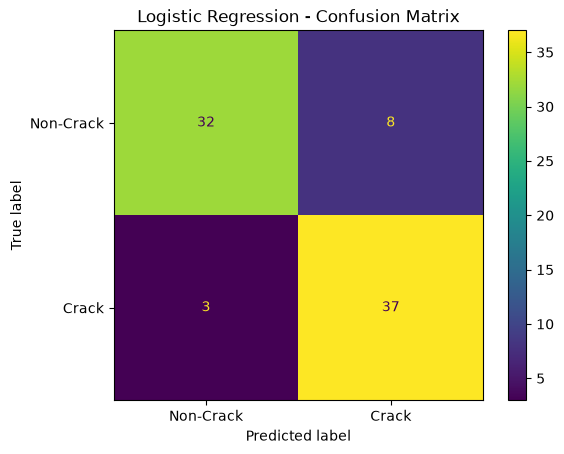

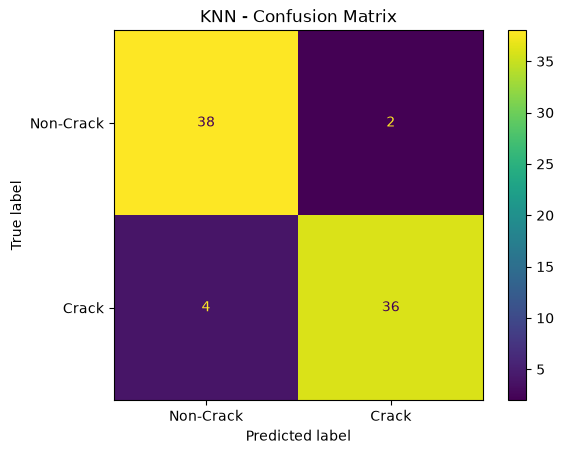

In [15]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

# Logistic Regression
ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred_logistic,
    display_labels=["Non-Crack", "Crack"]
)

plt.title("Logistic Regression - Confusion Matrix")
plt.show()


# KNN
ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred_knn,
    display_labels=["Non-Crack", "Crack"]
)

plt.title("KNN - Confusion Matrix")
plt.show()

<Figure size 700x500 with 0 Axes>

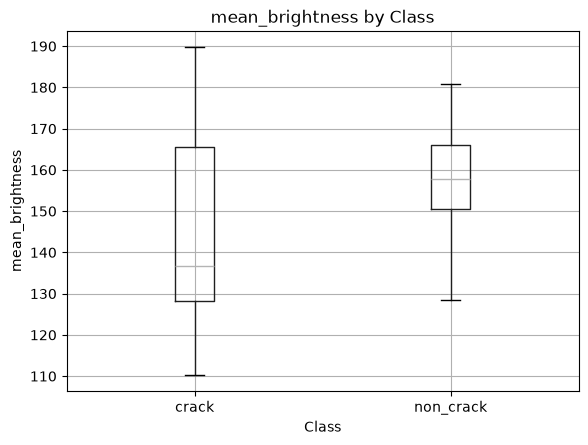

<Figure size 700x500 with 0 Axes>

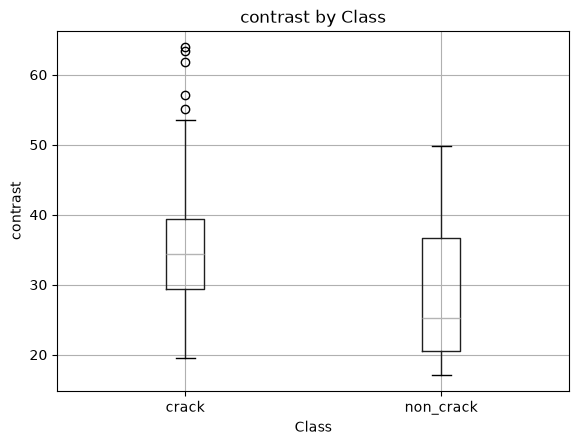

<Figure size 700x500 with 0 Axes>

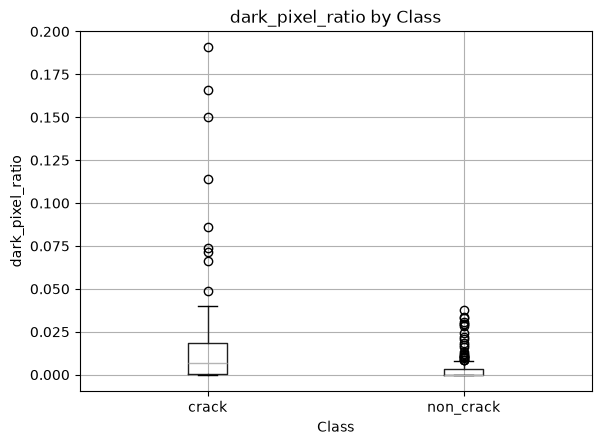

<Figure size 700x500 with 0 Axes>

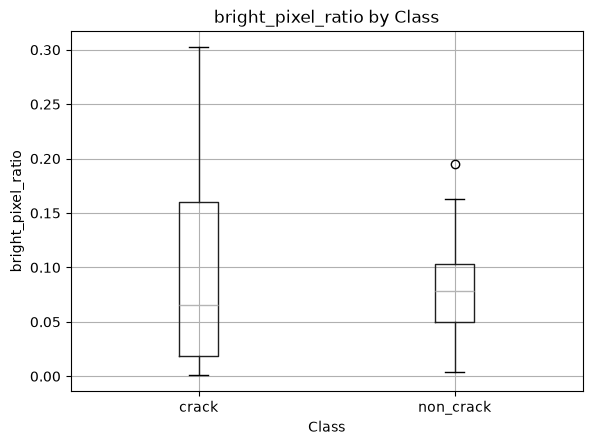

<Figure size 700x500 with 0 Axes>

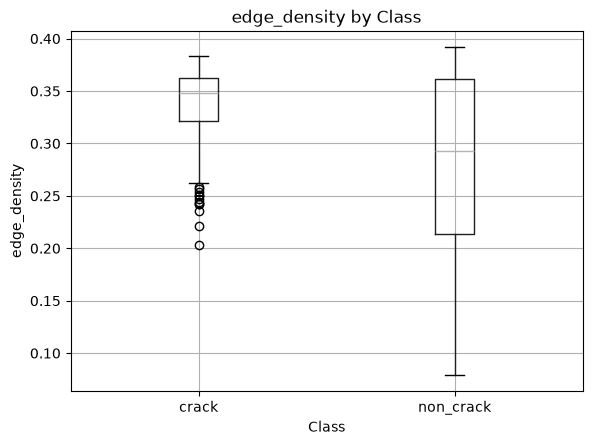

In [16]:
features_to_plot = [
    "mean_brightness",
    "contrast",
    "dark_pixel_ratio",
    "bright_pixel_ratio",
    "edge_density"
]

for feature in features_to_plot:
    plt.figure(figsize=(7, 5))

    df.boxplot(
        column=feature,
        by="class"
    )

    plt.title(f"{feature} by Class")
    plt.suptitle("")
    plt.xlabel("Class")
    plt.ylabel(feature)

    plt.show()

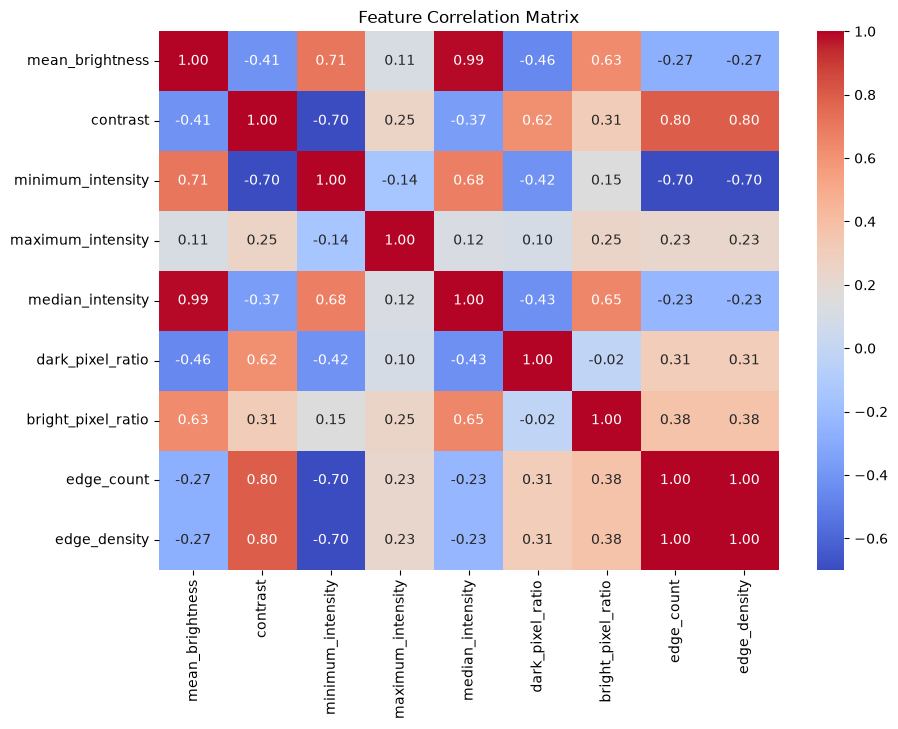

In [17]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10, 7))

correlation_matrix = X.corr()

sns.heatmap(
    correlation_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm"
)

plt.title("Feature Correlation Matrix")
plt.show()

## Part A — Results and Conclusion

Two traditional machine-learning models, Logistic Regression and K-Nearest Neighbors (KNN), were trained using statistical and edge-based features extracted from the asphalt images.

| Model | Accuracy | Precision | Recall | F1-Score | Training Time (s) | Prediction Time (s) |
|---|---:|---:|---:|---:|---:|---:|
| Logistic Regression | 0.8625 | 0.8222 | 0.9250 | 0.8706 | 0.0153 | 0.0005 |
| KNN | 0.9250 | 0.9474 | 0.9000 | 0.9231 | 0.0025 | 0.0028 |

KNN achieved higher accuracy, precision, and F1-score on the test set, while Logistic Regression achieved higher recall and faster prediction time. The Logistic Regression confusion matrix contained 32 true negatives, 8 false positives, 3 false negatives, and 37 true positives. The KNN confusion matrix contained 38 true negatives, 2 false positives, 4 false negatives, and 36 true positives. Thus, Logistic Regression produced fewer false negatives, while KNN produced fewer false positives.

The feature analysis showed that crack and non-crack images had differences in brightness, contrast, dark-pixel ratio, and edge density. The correlation analysis also showed some redundant features, such as mean brightness and median intensity (0.99 correlation), and edge count and edge density (1.00 correlation).

Overall, the experiment demonstrates that compact statistical and edge-based numerical features extracted from raw asphalt images can be used effectively with traditional machine-learning models for crack/non-crack classification.

# Part B

In [31]:
import pandas as pd

df_text = pd.read_csv(
    r"D:\MASTERS\FOML\assignment\202618026_AumTailor_DS605\202618026_lab_06\emails.csv"
)

print("Dataset shape:", df_text.shape)

print("\nColumn names:")
print(df_text.columns.tolist())

print("\nFirst 5 rows:")
print(df_text.head())

print("\nMissing values:")
print(df_text.isnull().sum())

Dataset shape: (5172, 3002)

Column names:
['Email No.', 'the', 'to', 'ect', 'and', 'for', 'of', 'a', 'you', 'hou', 'in', 'on', 'is', 'this', 'enron', 'i', 'be', 'that', 'will', 'have', 'with', 'your', 'at', 'we', 's', 'are', 'it', 'by', 'com', 'as', 'from', 'gas', 'or', 'not', 'me', 'deal', 'if', 'meter', 'hpl', 'please', 're', 'e', 'any', 'our', 'corp', 'can', 'd', 'all', 'has', 'was', 'know', 'need', 'an', 'forwarded', 'new', 't', 'may', 'up', 'j', 'mmbtu', 'should', 'do', 'am', 'get', 'out', 'see', 'no', 'there', 'price', 'daren', 'but', 'been', 'company', 'l', 'these', 'let', 'so', 'would', 'm', 'into', 'xls', 'farmer', 'attached', 'us', 'information', 'they', 'message', 'day', 'time', 'my', 'one', 'what', 'only', 'http', 'th', 'volume', 'mail', 'contract', 'which', 'month', 'more', 'robert', 'sitara', 'about', 'texas', 'nom', 'energy', 'pec', 'questions', 'www', 'deals', 'volumes', 'pm', 'ena', 'now', 'their', 'file', 'some', 'email', 'just', 'also', 'call', 'change', 'other', 'h

In [32]:
print("\nData types:")
print(df_text.dtypes.value_counts())

print("\nDuplicate rows:")
print(df_text.duplicated().sum())

print("\nTarget distribution:")
print(df_text["Prediction"].value_counts())

print("\nTarget proportions:")
print(df_text["Prediction"].value_counts(normalize=True))


Data types:
int64    3001
str         1
Name: count, dtype: int64

Duplicate rows:
0

Target distribution:
Prediction
0    3672
1    1500
Name: count, dtype: int64

Target proportions:
Prediction
0    0.709977
1    0.290023
Name: proportion, dtype: float64


In [33]:
df_text = df_text.drop(columns=["Email No."])

In [34]:
X_text = df_text.drop(columns=["Prediction"])
y_text = df_text["Prediction"]

print("Feature shape:", X_text.shape)
print("Target shape:", y_text.shape)

Feature shape: (5172, 3000)
Target shape: (5172,)


In [25]:
print("Duplicate rows:", df.duplicated().sum())

Duplicate rows: 0


In [35]:
from sklearn.model_selection import train_test_split

X_train_text, X_test_text, y_train_text, y_test_text = train_test_split(
    X_text,
    y_text,
    test_size=0.20,
    random_state=42,
    stratify=y_text
)

print("Training set:", X_train_text.shape)
print("Testing set:", X_test_text.shape)

Training set: (4137, 3000)
Testing set: (1035, 3000)


In [36]:
from sklearn.preprocessing import StandardScaler

scaler_text = StandardScaler()

X_train_text_scaled = scaler_text.fit_transform(X_train_text)
X_test_text_scaled = scaler_text.transform(X_test_text)

print("Training shape:", X_train_text_scaled.shape)
print("Testing shape:", X_test_text_scaled.shape)

Training shape: (4137, 3000)
Testing shape: (1035, 3000)


In [37]:
from sklearn.linear_model import LogisticRegression
import time

logistic_text = LogisticRegression(random_state=42)

start_time = time.perf_counter()

logistic_text.fit(X_train_text_scaled, y_train_text)

logistic_text_train_time = time.perf_counter() - start_time

print("Training time:", logistic_text_train_time, "seconds")

Training time: 0.9646091000004162 seconds


In [38]:
start_time = time.perf_counter()

y_pred_logistic_text = logistic_text.predict(X_test_text_scaled)

logistic_text_prediction_time = time.perf_counter() - start_time

print("Prediction time:", logistic_text_prediction_time, "seconds")

Prediction time: 0.006430800000089221 seconds


In [39]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)

logistic_text_accuracy = accuracy_score(
    y_test_text,
    y_pred_logistic_text
)

logistic_text_precision = precision_score(
    y_test_text,
    y_pred_logistic_text
)

logistic_text_recall = recall_score(
    y_test_text,
    y_pred_logistic_text
)

logistic_text_f1 = f1_score(
    y_test_text,
    y_pred_logistic_text
)

logistic_text_cm = confusion_matrix(
    y_test_text,
    y_pred_logistic_text
)

In [40]:
print("Logistic Regression Results")
print("---------------------------")
print("Accuracy :", logistic_text_accuracy)
print("Precision:", logistic_text_precision)
print("Recall   :", logistic_text_recall)
print("F1-Score :", logistic_text_f1)

print("\nConfusion Matrix:")
print(logistic_text_cm)

Logistic Regression Results
---------------------------
Accuracy : 0.966183574879227
Precision: 0.9206349206349206
Recall   : 0.9666666666666667
F1-Score : 0.943089430894309

Confusion Matrix:
[[710  25]
 [ 10 290]]


# KNN

In [41]:
from sklearn.neighbors import KNeighborsClassifier
import time

knn_text = KNeighborsClassifier(n_neighbors=5)

start_time = time.perf_counter()

knn_text.fit(X_train_text_scaled, y_train_text)

knn_text_train_time = time.perf_counter() - start_time

print("Training time:", knn_text_train_time, "seconds")

Training time: 0.08035079999990558 seconds


In [42]:
start_time = time.perf_counter()

y_pred_knn_text = knn_text.predict(X_test_text_scaled)

knn_text_prediction_time = time.perf_counter() - start_time

print("Prediction time:", knn_text_prediction_time, "seconds")

Prediction time: 2.2761324000002787 seconds


In [43]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)

knn_text_accuracy = accuracy_score(
    y_test_text,
    y_pred_knn_text
)

knn_text_precision = precision_score(
    y_test_text,
    y_pred_knn_text
)

knn_text_recall = recall_score(
    y_test_text,
    y_pred_knn_text
)

knn_text_f1 = f1_score(
    y_test_text,
    y_pred_knn_text
)

knn_text_cm = confusion_matrix(
    y_test_text,
    y_pred_knn_text
)

In [44]:
print("KNN Results")
print("-----------")
print("Accuracy :", knn_text_accuracy)
print("Precision:", knn_text_precision)
print("Recall   :", knn_text_recall)
print("F1-Score :", knn_text_f1)

print("\nConfusion Matrix:")
print(knn_text_cm)

KNN Results
-----------
Accuracy : 0.8338164251207729
Precision: 0.6434977578475336
Recall   : 0.9566666666666667
F1-Score : 0.7694369973190348

Confusion Matrix:
[[576 159]
 [ 13 287]]


Convert the existing word counts to TF-IDF

In [45]:
from sklearn.feature_extraction.text import TfidfTransformer

tfidf = TfidfTransformer()

In [46]:
X_train_tfidf = tfidf.fit_transform(X_train_text)

X_test_tfidf = tfidf.transform(X_test_text)

print("Training TF-IDF shape:", X_train_tfidf.shape)
print("Testing TF-IDF shape:", X_test_tfidf.shape)

Training TF-IDF shape: (4137, 3000)
Testing TF-IDF shape: (1035, 3000)


In [47]:
from sklearn.linear_model import LogisticRegression
import time

logistic_tfidf = LogisticRegression(random_state=42)

start_time = time.perf_counter()

logistic_tfidf.fit(X_train_tfidf, y_train_text)

logistic_tfidf_train_time = time.perf_counter() - start_time

print("Training time:", logistic_tfidf_train_time, "seconds")

Training time: 0.07551019999937125 seconds


In [48]:
start_time = time.perf_counter()

y_pred_logistic_tfidf = logistic_tfidf.predict(X_test_tfidf)

logistic_tfidf_prediction_time = time.perf_counter() - start_time

print("Prediction time:", logistic_tfidf_prediction_time, "seconds")

Prediction time: 0.0013094999994791579 seconds


In [49]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)

logistic_tfidf_accuracy = accuracy_score(
    y_test_text,
    y_pred_logistic_tfidf
)

logistic_tfidf_precision = precision_score(
    y_test_text,
    y_pred_logistic_tfidf
)

logistic_tfidf_recall = recall_score(
    y_test_text,
    y_pred_logistic_tfidf
)

logistic_tfidf_f1 = f1_score(
    y_test_text,
    y_pred_logistic_tfidf
)

logistic_tfidf_cm = confusion_matrix(
    y_test_text,
    y_pred_logistic_tfidf
)

In [50]:
print("TF-IDF Logistic Regression Results")
print("----------------------------------")
print("Accuracy :", logistic_tfidf_accuracy)
print("Precision:", logistic_tfidf_precision)
print("Recall   :", logistic_tfidf_recall)
print("F1-Score :", logistic_tfidf_f1)

print("\nConfusion Matrix:")
print(logistic_tfidf_cm)

TF-IDF Logistic Regression Results
----------------------------------
Accuracy : 0.9507246376811594
Precision: 0.9307958477508651
Recall   : 0.8966666666666666
F1-Score : 0.9134125636672326

Confusion Matrix:
[[715  20]
 [ 31 269]]


# KNN with TF-IDF

In [51]:
from sklearn.neighbors import KNeighborsClassifier
import time

knn_tfidf = KNeighborsClassifier(n_neighbors=5)

start_time = time.perf_counter()

knn_tfidf.fit(X_train_tfidf, y_train_text)

knn_tfidf_train_time = time.perf_counter() - start_time

print("Training time:", knn_tfidf_train_time, "seconds")

Training time: 0.0051119999998263665 seconds


In [52]:
start_time = time.perf_counter()

y_pred_knn_tfidf = knn_tfidf.predict(X_test_tfidf)

knn_tfidf_prediction_time = time.perf_counter() - start_time

print("Prediction time:", knn_tfidf_prediction_time, "seconds")

Prediction time: 0.29824290000033216 seconds


In [53]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)

knn_tfidf_accuracy = accuracy_score(
    y_test_text,
    y_pred_knn_tfidf
)

knn_tfidf_precision = precision_score(
    y_test_text,
    y_pred_knn_tfidf
)

knn_tfidf_recall = recall_score(
    y_test_text,
    y_pred_knn_tfidf
)

knn_tfidf_f1 = f1_score(
    y_test_text,
    y_pred_knn_tfidf
)

knn_tfidf_cm = confusion_matrix(
    y_test_text,
    y_pred_knn_tfidf
)

In [54]:
print("TF-IDF KNN Results")
print("------------------")
print("Accuracy :", knn_tfidf_accuracy)
print("Precision:", knn_tfidf_precision)
print("Recall   :", knn_tfidf_recall)
print("F1-Score :", knn_tfidf_f1)

print("\nConfusion Matrix:")
print(knn_tfidf_cm)

TF-IDF KNN Results
------------------
Accuracy : 0.8946859903381642
Precision: 0.7784256559766763
Recall   : 0.89
F1-Score : 0.8304821150855366

Confusion Matrix:
[[659  76]
 [ 33 267]]


In [55]:
print("Word Frequency - Logistic Regression")
print("Training time :", logistic_text_train_time)
print("Prediction time:", logistic_text_prediction_time)

print("\nWord Frequency - KNN")
print("Training time :", knn_text_train_time)
print("Prediction time:", knn_text_prediction_time)

print("\nTF-IDF - Logistic Regression")
print("Training time :", logistic_tfidf_train_time)
print("Prediction time:", logistic_tfidf_prediction_time)

print("\nTF-IDF - KNN")
print("Training time :", knn_tfidf_train_time)
print("Prediction time:", knn_tfidf_prediction_time)

print("\nNumber of features:", X_train_text.shape[1])

Word Frequency - Logistic Regression
Training time : 0.9646091000004162
Prediction time: 0.006430800000089221

Word Frequency - KNN
Training time : 0.08035079999990558
Prediction time: 2.2761324000002787

TF-IDF - Logistic Regression
Training time : 0.07551019999937125
Prediction time: 0.0013094999994791579

TF-IDF - KNN
Training time : 0.0051119999998263665
Prediction time: 0.29824290000033216

Number of features: 3000


In [56]:
feature_frequency = (X_train_text > 0).sum(axis=0)

print("Total features:", X_train_text.shape[1])
print("\nFrequency summary:")
print(feature_frequency.describe())

Total features: 3000

Frequency summary:
count    3000.000000
mean      234.079667
std       582.216315
min         1.000000
25%        26.000000
50%        52.000000
75%       139.000000
max      4137.000000
dtype: float64


In [57]:
min_frequency = 10

selected_features = feature_frequency[
    feature_frequency >= min_frequency
].index

X_train_reduced = X_train_text[selected_features]
X_test_reduced = X_test_text[selected_features]

print("Original number of features:", X_train_text.shape[1])
print("Reduced number of features:", X_train_reduced.shape[1])

Original number of features: 3000
Reduced number of features: 2912


In [58]:
from sklearn.feature_extraction.text import TfidfTransformer

tfidf_reduced = TfidfTransformer()

X_train_reduced_tfidf = tfidf_reduced.fit_transform(
    X_train_reduced
)

X_test_reduced_tfidf = tfidf_reduced.transform(
    X_test_reduced
)

print("Training shape:", X_train_reduced_tfidf.shape)
print("Testing shape:", X_test_reduced_tfidf.shape)

Training shape: (4137, 2912)
Testing shape: (1035, 2912)


# Train improved Logistic Regression

In [59]:
from sklearn.linear_model import LogisticRegression
import time

logistic_reduced = LogisticRegression(random_state=42)

start_time = time.perf_counter()

logistic_reduced.fit(
    X_train_reduced_tfidf,
    y_train_text
)

logistic_reduced_train_time = time.perf_counter() - start_time

print("Training time:", logistic_reduced_train_time, "seconds")

Training time: 0.08947290000014618 seconds


In [60]:
start_time = time.perf_counter()

y_pred_logistic_reduced = logistic_reduced.predict(
    X_test_reduced_tfidf
)

logistic_reduced_prediction_time = time.perf_counter() - start_time

print("Prediction time:", logistic_reduced_prediction_time, "seconds")


Prediction time: 0.001108399999793619 seconds


In [61]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)

logistic_reduced_accuracy = accuracy_score(
    y_test_text,
    y_pred_logistic_reduced
)

logistic_reduced_precision = precision_score(
    y_test_text,
    y_pred_logistic_reduced
)

logistic_reduced_recall = recall_score(
    y_test_text,
    y_pred_logistic_reduced
)

logistic_reduced_f1 = f1_score(
    y_test_text,
    y_pred_logistic_reduced
)

logistic_reduced_cm = confusion_matrix(
    y_test_text,
    y_pred_logistic_reduced
)

In [62]:
print("Improved TF-IDF Logistic Regression")
print("-----------------------------------")
print("Accuracy :", logistic_reduced_accuracy)
print("Precision:", logistic_reduced_precision)
print("Recall   :", logistic_reduced_recall)
print("F1-Score :", logistic_reduced_f1)

print("\nConfusion Matrix:")
print(logistic_reduced_cm)

print("\nTraining time :", logistic_reduced_train_time)
print("Prediction time:", logistic_reduced_prediction_time)

Improved TF-IDF Logistic Regression
-----------------------------------
Accuracy : 0.9507246376811594
Precision: 0.9307958477508651
Recall   : 0.8966666666666666
F1-Score : 0.9134125636672326

Confusion Matrix:
[[715  20]
 [ 31 269]]

Training time : 0.08947290000014618
Prediction time: 0.001108399999793619


Reduce the vocabulary further

In [63]:
min_frequency = 50

selected_features_50 = feature_frequency[
    feature_frequency >= min_frequency
].index

X_train_reduced_50 = X_train_text[selected_features_50]
X_test_reduced_50 = X_test_text[selected_features_50]

print("Original number of features:", X_train_text.shape[1])
print("Reduced number of features:", X_train_reduced_50.shape[1])
print("Features removed:", 
      X_train_text.shape[1] - X_train_reduced_50.shape[1])

Original number of features: 3000
Reduced number of features: 1551
Features removed: 1449


In [65]:
# ============================================================
# PART C - TF-IDF + REDUCED VOCABULARY
# ============================================================

from sklearn.feature_extraction.text import TfidfTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)
import time


# ------------------------------------------------------------
# 1. Convert reduced word-frequency data to TF-IDF
# ------------------------------------------------------------

tfidf_reduced_50 = TfidfTransformer()

X_train_reduced_50_tfidf = tfidf_reduced_50.fit_transform(
    X_train_reduced_50
)

X_test_reduced_50_tfidf = tfidf_reduced_50.transform(
    X_test_reduced_50
)

print("Training TF-IDF shape:", X_train_reduced_50_tfidf.shape)
print("Testing TF-IDF shape :", X_test_reduced_50_tfidf.shape)


# ------------------------------------------------------------
# 2. Train Logistic Regression
# ------------------------------------------------------------

logistic_reduced_50 = LogisticRegression(
    random_state=42
)

start_time = time.perf_counter()

logistic_reduced_50.fit(
    X_train_reduced_50_tfidf,
    y_train_text
)

logistic_reduced_50_train_time = (
    time.perf_counter() - start_time
)


# ------------------------------------------------------------
# 3. Prediction
# ------------------------------------------------------------

start_time = time.perf_counter()

y_pred_logistic_reduced_50 = (
    logistic_reduced_50.predict(
        X_test_reduced_50_tfidf
    )
)

logistic_reduced_50_prediction_time = (
    time.perf_counter() - start_time
)


# ------------------------------------------------------------
# 4. Calculate evaluation metrics
# ------------------------------------------------------------

logistic_reduced_50_accuracy = accuracy_score(
    y_test_text,
    y_pred_logistic_reduced_50
)

logistic_reduced_50_precision = precision_score(
    y_test_text,
    y_pred_logistic_reduced_50
)

logistic_reduced_50_recall = recall_score(
    y_test_text,
    y_pred_logistic_reduced_50
)

logistic_reduced_50_f1 = f1_score(
    y_test_text,
    y_pred_logistic_reduced_50
)

logistic_reduced_50_cm = confusion_matrix(
    y_test_text,
    y_pred_logistic_reduced_50
)


# ------------------------------------------------------------
# 5. Display Part C results
# ------------------------------------------------------------

print("\n==========================================")
print("PART C - IMPROVED REPRESENTATION")
print("==========================================")

print("\nFeature Information")
print("-------------------")
print("Original features :", X_train_text.shape[1])
print("Reduced features  :", X_train_reduced_50.shape[1])
print(
    "Features removed  :",
    X_train_text.shape[1] - X_train_reduced_50.shape[1]
)

print("\nModel Performance")
print("-----------------")
print("Accuracy :", logistic_reduced_50_accuracy)
print("Precision:", logistic_reduced_50_precision)
print("Recall   :", logistic_reduced_50_recall)
print("F1-Score :", logistic_reduced_50_f1)

print("\nComputation Time")
print("----------------")
print(
    "Training time  :",
    logistic_reduced_50_train_time,
    "seconds"
)
print(
    "Prediction time:",
    logistic_reduced_50_prediction_time,
    "seconds"
)

print("\nConfusion Matrix")
print("----------------")
print(logistic_reduced_50_cm)

Training TF-IDF shape: (4137, 1551)
Testing TF-IDF shape : (1035, 1551)

PART C - IMPROVED REPRESENTATION

Feature Information
-------------------
Original features : 3000
Reduced features  : 1551
Features removed  : 1449

Model Performance
-----------------
Accuracy : 0.9458937198067633
Precision: 0.9236111111111112
Recall   : 0.8866666666666667
F1-Score : 0.9047619047619048

Computation Time
----------------
Training time  : 0.06264259999989008 seconds
Prediction time: 0.0006370999999489868 seconds

Confusion Matrix
----------------
[[713  22]
 [ 34 266]]


## Final Part B table

In [66]:
import pandas as pd

part_b_results = pd.DataFrame({
    "Representation": [
        "Word Frequency",
        "Word Frequency",
        "TF-IDF",
        "TF-IDF"
    ],
    "Model": [
        "Logistic Regression",
        "KNN",
        "Logistic Regression",
        "KNN"
    ],
    "Accuracy": [
        logistic_text_accuracy,
        knn_text_accuracy,
        logistic_tfidf_accuracy,
        knn_tfidf_accuracy
    ],
    "Precision": [
        logistic_text_precision,
        knn_text_precision,
        logistic_tfidf_precision,
        knn_tfidf_precision
    ],
    "Recall": [
        logistic_text_recall,
        knn_text_recall,
        logistic_tfidf_recall,
        knn_tfidf_recall
    ],
    "F1": [
        logistic_text_f1,
        knn_text_f1,
        logistic_tfidf_f1,
        knn_tfidf_f1
    ],
    "Training Time (s)": [
        logistic_text_train_time,
        knn_text_train_time,
        logistic_tfidf_train_time,
        knn_tfidf_train_time
    ],
    "Prediction Time (s)": [
        logistic_text_prediction_time,
        knn_text_prediction_time,
        logistic_tfidf_prediction_time,
        knn_tfidf_prediction_time
    ],
    "Features": [3000, 3000, 3000, 3000]
})

print(part_b_results.round(4))

   Representation                Model  Accuracy  Precision  Recall      F1  \
0  Word Frequency  Logistic Regression    0.9662     0.9206  0.9667  0.9431   
1  Word Frequency                  KNN    0.8338     0.6435  0.9567  0.7694   
2          TF-IDF  Logistic Regression    0.9507     0.9308  0.8967  0.9134   
3          TF-IDF                  KNN    0.8947     0.7784  0.8900  0.8305   

   Training Time (s)  Prediction Time (s)  Features  
0             0.9646               0.0064      3000  
1             0.0804               2.2761      3000  
2             0.0755               0.0013      3000  
3             0.0051               0.2982      3000  


In [67]:
part_c_results = pd.DataFrame({
    "Approach": [
        "Original TF-IDF",
        "Reduced TF-IDF"
    ],
    "Features": [
        3000,
        X_train_reduced_50.shape[1]
    ],
    "Features Removed": [
        0,
        3000 - X_train_reduced_50.shape[1]
    ],
    "Accuracy": [
        logistic_tfidf_accuracy,
        logistic_reduced_50_accuracy
    ],
    "Precision": [
        logistic_tfidf_precision,
        logistic_reduced_50_precision
    ],
    "Recall": [
        logistic_tfidf_recall,
        logistic_reduced_50_recall
    ],
    "F1": [
        logistic_tfidf_f1,
        logistic_reduced_50_f1
    ],
    "Training Time (s)": [
        logistic_tfidf_train_time,
        logistic_reduced_50_train_time
    ],
    "Prediction Time (s)": [
        logistic_tfidf_prediction_time,
        logistic_reduced_50_prediction_time
    ]
})

print(part_c_results.round(4))

          Approach  Features  Features Removed  Accuracy  Precision  Recall  \
0  Original TF-IDF      3000                 0    0.9507     0.9308  0.8967   
1   Reduced TF-IDF      1551              1449    0.9459     0.9236  0.8867   

       F1  Training Time (s)  Prediction Time (s)  
0  0.9134             0.0755               0.0013  
1  0.9048             0.0626               0.0006  


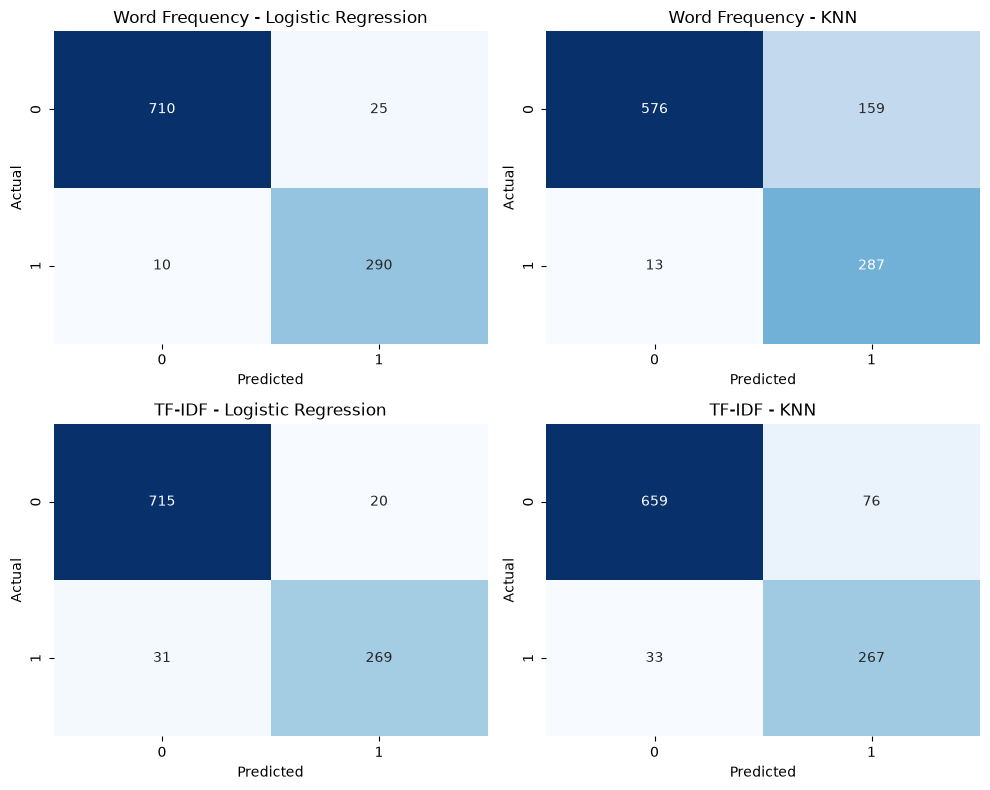

In [68]:
import matplotlib.pyplot as plt
import seaborn as sns

fig, axes = plt.subplots(2, 2, figsize=(10, 8))

confusion_matrices = [
    (logistic_text_cm, "Word Frequency - Logistic Regression"),
    (confusion_matrix(y_test_text, y_pred_knn_text), "Word Frequency - KNN"),
    (logistic_tfidf_cm, "TF-IDF - Logistic Regression"),
    (confusion_matrix(y_test_text, y_pred_knn_tfidf), "TF-IDF - KNN")
]

for ax, (cm, title) in zip(axes.ravel(), confusion_matrices):
    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        cbar=False,
        ax=ax
    )
    ax.set_title(title)
    ax.set_xlabel("Predicted")
    ax.set_ylabel("Actual")

plt.tight_layout()
plt.show()

# Conclusion


Looking at the results, the main thing I observed is that how we represent the data has a direct effect on how well the model performs.

For the image data, using simple intensity and edge-based features was enough to capture useful differences between crack and non-crack images. KNN performed better than Logistic Regression on these features, achieving 92.50% accuracy.

For the email data, Logistic Regression worked better than KNN with both word-frequency and TF-IDF representations. The word-frequency representation with Logistic Regression achieved 96.62% accuracy and an F1-score of 94.31%.

I also tried reducing the number of text features by removing words that appeared in fewer than 50 emails. This reduced the features from 3,000 to 1,551 and made the model faster, but there was a small drop in performance. This shows that some of the removed features, even though they were less frequent, still contained useful information.

Overall, the results show that there is a trade-off between keeping more information for better prediction and reducing the data to make the model faster and simpler.